# 01. Data and TF-IDF baseline

This notebook loads the Fake News Filipino corpus (Cruz et al., 2020), removes duplicate articles,
makes one fixed train/validation/test split, and trains the classic baseline: TF-IDF features with
logistic regression. Notebooks 02 and 03 rebuild the same split and check it against the fingerprint
saved here, so every model is scored on the same test articles.

Label convention: `1` = fake, `0` = real. The dataset card does not name the labels. This mapping comes
from reading samples: label 0 reads like the tabloid sources the paper lists (Abante, Bandera,
Pilipino Star Ngayon), and label 1 reads like the blog-style sites flagged by Vera Files and NUJP.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
from fakenews_data import (
    DATASET_REVISION, LABEL_NAMES, SEED,
    drop_duplicates, load_articles, make_splits, split_fingerprint, word_count,
)

DATA_DIR = REPO_ROOT / "data" / "raw"
RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Load the data

The data is downloaded at run time from a pinned revision on Hugging Face. The dataset has no stated
license, so this repo does not store a copy.

In [2]:
raw = load_articles(DATA_DIR)

print(f"Rows: {len(raw)}")
print(raw["label"].map(LABEL_NAMES).value_counts())

Rows: 3206
label
Real    1603
Fake    1603
Name: count, dtype: int64


## Remove duplicate articles

Some articles appear more than once. If a duplicate lands in both the training and test sets, the
model is tested on text it has already seen, and the scores come out too high. Duplicates are dropped
before splitting.

In [3]:
duplicate_mask = raw.duplicated(subset="article", keep="first")
duplicates = raw[duplicate_mask]

conflicting = raw.groupby("article")["label"].nunique()
print(f"Duplicate rows removed: {len(duplicates)}")
print(f"Articles with conflicting labels: {(conflicting > 1).sum()}")
print("Duplicates by label:")
print(duplicates["label"].map(LABEL_NAMES).value_counts())

articles = drop_duplicates(raw)
print(f"Unique articles kept: {len(articles)}")

Duplicate rows removed: 201
Articles with conflicting labels: 0
Duplicates by label:
label
Real    107
Fake     94
Name: count, dtype: int64
Unique articles kept: 3005


## Split 70 / 15 / 15

The split is stratified by label, so each part keeps the same real-to-fake ratio. The validation set
picks hyperparameters. The test set is used once per model, at the end.

In [4]:
train_df, val_df, test_df = make_splits(articles)

split_summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "articles": [len(train_df), len(val_df), len(test_df)],
    "fake_share": [train_df["label"].mean(), val_df["label"].mean(), test_df["label"].mean()],
})
print(split_summary.round(3).to_string(index=False))

split  articles  fake_share
train      2103       0.502
  val       451       0.503
 test       451       0.501


The fingerprint is a hash of the sorted test articles. Notebooks 02 and 03 recompute it and stop if
it does not match.

In [5]:
fingerprint = {
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,
    "unique_articles": len(articles),
    "train": len(train_df),
    "val": len(val_df),
    "test": len(test_df),
    "test_fingerprint": split_fingerprint(test_df),
}
(RESULTS_DIR / "split_fingerprint.json").write_text(json.dumps(fingerprint, indent=2))
print(json.dumps(fingerprint, indent=2))

{
  "dataset_revision": "9d489de0df0f7215914660b00d478a4e2069e850",
  "seed": 42,
  "unique_articles": 3005,
  "train": 2103,
  "val": 451,
  "test": 451,
  "test_fingerprint": "1c312f3fbfe62465"
}


## Article length

Length matters for the transformer models later, since they read at most 512 tokens.

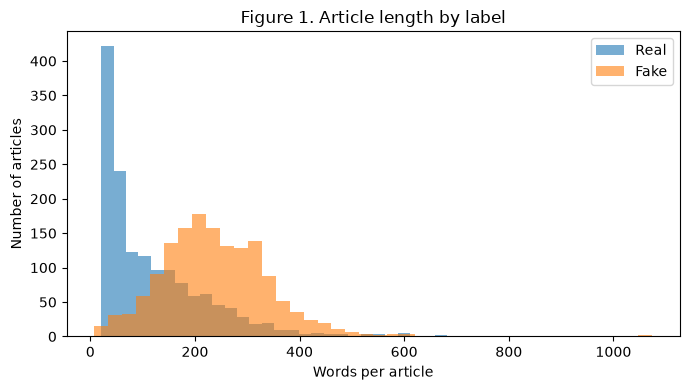

        count   mean    std   min    25%    50%    75%     max
label                                                         
Fake   1509.0  240.0  105.0   8.0  171.0  229.0  303.0  1074.0
Real   1496.0  121.0  106.0  21.0   42.0   84.0  171.0   965.0


In [6]:
word_counts = word_count(articles["article"])

fig, ax = plt.subplots(figsize=(7, 4))
for label, name in LABEL_NAMES.items():
    ax.hist(word_counts[articles["label"] == label], bins=40, alpha=0.6, label=name)
ax.set_xlabel("Words per article")
ax.set_ylabel("Number of articles")
ax.set_title("Figure 1. Article length by label")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_article_length.png", dpi=150)
plt.show()

print(word_counts.groupby(articles["label"].map(LABEL_NAMES)).describe().round(0))

## Baseline: TF-IDF + logistic regression

TF-IDF turns each article into a vector of word and word-pair weights. A word gets a high weight when
it is frequent in that article but rare across the corpus. Logistic regression then learns one weight
per feature. The regularization strength `C` is chosen on the validation set by macro F1, which is the
unweighted mean of the F1 scores for the two classes.

In [7]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df["article"])
X_val = vectorizer.transform(val_df["article"])
X_test = vectorizer.transform(test_df["article"])
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")

search_rows = []
for C in [0.1, 0.3, 1, 3, 10, 30, 100]:
    model = LogisticRegression(C=C, max_iter=2000)
    model.fit(X_train, y_train)
    val_pred = model.predict(X_val)
    search_rows.append({
        "C": C,
        "val_accuracy": accuracy_score(y_val, val_pred),
        "val_macro_f1": f1_score(y_val, val_pred, average="macro"),
    })

search = pd.DataFrame(search_rows)
print(search.round(4).to_string(index=False))

best_C = search.loc[search["val_macro_f1"].idxmax(), "C"]
print(f"Best C: {best_C}")

Vocabulary size: 54577


    C  val_accuracy  val_macro_f1
  0.1        0.9024        0.9023
  0.3        0.9157        0.9156
  1.0        0.9446        0.9446
  3.0        0.9579        0.9579
 10.0        0.9667        0.9667
 30.0        0.9667        0.9667
100.0        0.9579        0.9579
Best C: 10.0


In [8]:
baseline = LogisticRegression(C=best_C, max_iter=2000)
baseline.fit(X_train, y_train)

val_pred = baseline.predict(X_val)
test_pred = baseline.predict(X_test)

metrics = pd.DataFrame([
    {"model": "tfidf_logreg", "split": "val", "n": len(y_val),
     "accuracy": accuracy_score(y_val, val_pred), "macro_f1": f1_score(y_val, val_pred, average="macro")},
    {"model": "tfidf_logreg", "split": "test", "n": len(y_test),
     "accuracy": accuracy_score(y_test, test_pred), "macro_f1": f1_score(y_test, test_pred, average="macro")},
])
metrics.to_csv(RESULTS_DIR / "metrics_tfidf_logreg.csv", index=False)
print(metrics.round(4).to_string(index=False))

       model split   n  accuracy  macro_f1
tfidf_logreg   val 451    0.9667    0.9667
tfidf_logreg  test 451    0.9623    0.9623


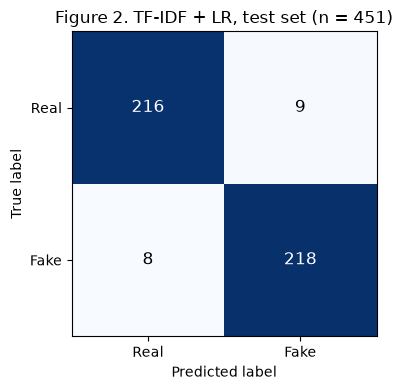

In [9]:
cm = confusion_matrix(y_test, test_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color, fontsize=12)
ax.set_xticks([0, 1], [LABEL_NAMES[0], LABEL_NAMES[1]])
ax.set_yticks([0, 1], [LABEL_NAMES[0], LABEL_NAMES[1]])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(f"Figure 2. TF-IDF + LR, test set (n = {len(y_test)})")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig2_confusion_tfidf_logreg.png", dpi=150)
plt.show()

## What the baseline relies on

The largest positive weights push an article toward "fake" and the largest negative weights push it
toward "real". If these are site names, bylines, or boilerplate, the model is detecting the source
website rather than fake content. That would also inflate the scores of the larger models.

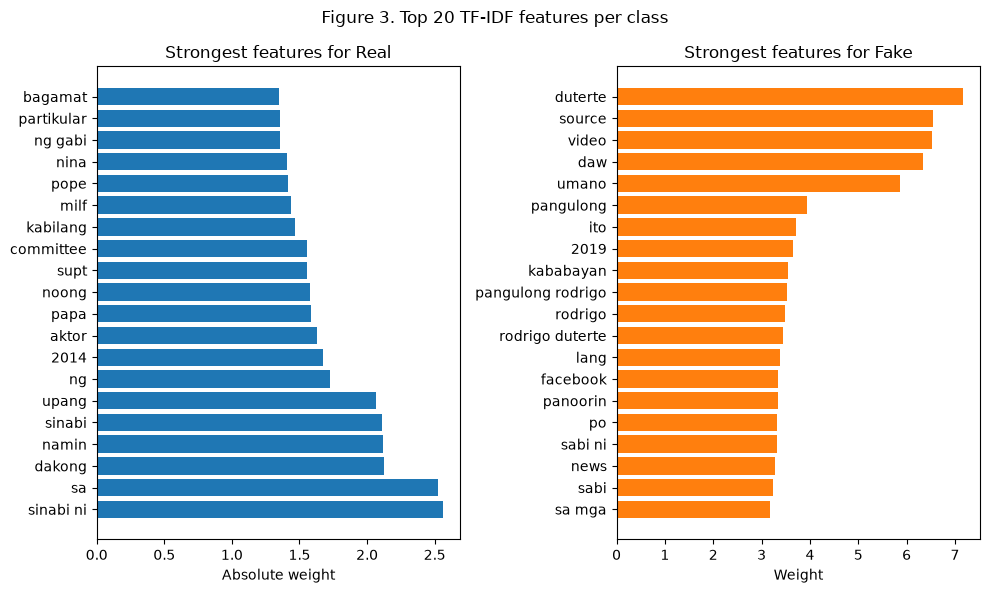

real_feature  real_weight      fake_feature  fake_weight
   sinabi ni       -2.560           duterte        7.159
          sa       -2.526            source        6.539
      dakong       -2.127             video        6.516
       namin       -2.119               daw        6.331
      sinabi       -2.111             umano        5.866
       upang       -2.063         pangulong        3.930
          ng       -1.729               ito        3.715
        2014       -1.677              2019        3.654
       aktor       -1.631         kababayan        3.550
        papa       -1.588 pangulong rodrigo        3.528
       noong       -1.581           rodrigo        3.481
        supt       -1.556   rodrigo duterte        3.453
   committee       -1.553              lang        3.376
    kabilang       -1.466          facebook        3.345
        milf       -1.439          panoorin        3.336
        pope       -1.418                po        3.328
        nina       -1.409      

In [10]:
feature_names = np.array(vectorizer.get_feature_names_out())
weights = baseline.coef_[0]
top_k = 20

top_fake = np.argsort(weights)[-top_k:]
top_real = np.argsort(weights)[:top_k]

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].barh(feature_names[top_real], -weights[top_real], color="tab:blue")
axes[0].set_title("Strongest features for Real")
axes[0].set_xlabel("Absolute weight")
axes[1].barh(feature_names[top_fake], weights[top_fake], color="tab:orange")
axes[1].set_title("Strongest features for Fake")
axes[1].set_xlabel("Weight")
fig.suptitle("Figure 3. Top 20 TF-IDF features per class")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig3_top_features.png", dpi=150)
plt.show()

top_features = pd.DataFrame({
    "real_feature": feature_names[top_real],
    "real_weight": weights[top_real].round(3),
    "fake_feature": feature_names[top_fake][::-1],
    "fake_weight": weights[top_fake][::-1].round(3),
})
top_features.to_csv(RESULTS_DIR / "top_features_tfidf_logreg.csv", index=False)
print(top_features.to_string(index=False))

Many of these features describe the source or the period, not the claim. "2014" points to real news
and "2019", "duterte", "video", "facebook", and "panoorin" (watch) point to fake news. Notebook 02
measures how much of the 0.96 score comes from these shortcuts.